# Pre-entrega: Pipeline de entrenamiento, validación y clasificador base

**Proyecto· Deep Learning**

**Autor:** Vicleniz Diaz Luque ·

**Fecha:** 18/10/2026

## Objetivo
Construir un pipeline reproducible de entrenamiento y validación en PyTorch, con un clasificador base (MLP) y un loop de entrenamiento explícito con autograd y Adam.

## Problema
Dado el **título** de una publicación de Mercado Libre, predecir su **categoría** (clasificación multiclase, 8 clases).

## Dataset
`dataset_1.csv`: 3.556 títulos únicos con columnas `id_base`, `titulo` y `categoria`. Se leen desde Google Drive.

## Contenido del notebook
1. Configuración del entorno (dispositivo y semillas)
2. Carga de datos
3. Split train/validación y vectorización TF-IDF
4. Arquitectura base (MLP)
5. Funciones de entrenamiento y validación
6. Entrenamiento con Adam
7. Curvas de pérdida y accuracy
8. Evaluación final
9. Resultados e interpretación




In [39]:
## 1. Configuracion del Entorno
#imports y versión de PyTorch

import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from torch.utils.data import DataLoader, TensorDataset

print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


In [40]:
## 2. #configuración, dispositivo y semillas
@dataclass
class Config:
    seed: int = 42
    val_size: float = 0.2
    max_features: int = 5000
    hidden_dim: int = 128
    dropout: float = 0.3
    batch_size: int = 64
    epochs: int = 30
    learning_rate: float = 1e-3

cfg = Config()


def get_device() -> torch.device:
    """Detecta automáticamente el mejor dispositivo: CUDA > MPS > CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    """Fija semillas de Python, NumPy y PyTorch para reproducibilidad."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)
device = get_device()
print("Dispositivo:", device)

Dispositivo: cpu


In [42]:
## 3. #cargar el dataset desde Drive
from google.colab import drive
drive.mount("/content/drive")

# Ajustá esta ruta a donde guardaste el archivo en tu Drive
DATA_PATH = "/content/drive/MyDrive/Data Science III: NLP & Deep Learning aplicado a Ciencia de Datos/dataset_1.csv"

df = pd.read_csv(DATA_PATH).dropna(subset=["titulo", "categoria"])
print(df.shape)
df.sample(5, random_state=0)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(3556, 3)


,id_base,titulo,categoria
989,MLA2366903286,Combo X6 Sillas Alta Retro A Cuadros De Acero ...,jardin_aire_libre
463,MLA1913375793,Freidora De Aire Horno 11 Litros Novohome Airf...,peq_electrodomesticos
958,MLA2080436294,Zapatero Botinero Extensible Organizador De Ca...,muebles
196,MLA1951479466,Sandwichera Tostadora Eléctrica Novohome Sm400...,peq_electrodomesticos
825,MLA1788402821,Combo Remington Secador De Pelo 2000 W + Cepil...,artefactos_cabello


In [43]:
## 4. #split train/validación y vectorización
classes = sorted(df["categoria"].unique())
label2idx = {c: i for i, c in enumerate(classes)}
y = df["categoria"].map(label2idx).to_numpy()

x_tr_txt, x_val_txt, y_tr, y_val = train_test_split(
    df["titulo"].to_numpy(), y,
    test_size=cfg.val_size, stratify=y, random_state=cfg.seed,
)

vectorizer = TfidfVectorizer(
    max_features=cfg.max_features, ngram_range=(1, 2), min_df=2,
    strip_accents="unicode", sublinear_tf=True,
)
x_tr = vectorizer.fit_transform(x_tr_txt).toarray().astype(np.float32)
x_val = vectorizer.transform(x_val_txt).toarray().astype(np.float32)

weights = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_tr)
class_weights = torch.tensor(weights, dtype=torch.float32)

train_ds = TensorDataset(torch.from_numpy(x_tr), torch.from_numpy(y_tr).long())
val_ds = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val).long())

g = torch.Generator().manual_seed(cfg.seed)
train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False)

input_dim = x_tr.shape[1]
print(f"Train: {len(train_ds)} | Validación: {len(val_ds)} | Features: {input_dim} | Clases: {len(classes)}")

Train: 2844 | Validación: 712 | Features: 5000 | Clases: 8


In [44]:
## 5. #arquitectura base (MLP)
class MLPClassifier(nn.Module):
    """input_dim -> hidden_dim -> n_classes. Devuelve logits (sin softmax)."""

    def __init__(self, input_dim, hidden_dim, n_classes, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_classes),
        )

    def forward(self, x):
        return self.net(x)


model = MLPClassifier(input_dim, cfg.hidden_dim, len(classes), cfg.dropout).to(device)
print(model)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

MLPClassifier(
  (net): Sequential(
    (0): Linear(in_features=5000, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)
Parámetros: 641160


In [45]:
## 6. #funciones de entrenamiento y validación
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()           # 1. reiniciar gradientes acumulados
        logits = model(xb)              # 2. forward pass
        loss = criterion(logits, yb)    # 3. cálculo de la pérdida
        loss.backward()                 # 4. backward pass (autograd)
        optimizer.step()                # 5. actualización de pesos con Adam

        running_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Evalúa en datos no vistos: sin gradientes y con el modelo en modo eval."""
    model.eval()
    running_loss, total = 0.0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)

        running_loss += loss.item() * xb.size(0)
        total += xb.size(0)
        y_true.extend(yb.cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    metrics = {
        "loss": running_loss / total,
        "accuracy": sum(t == p for t, p in zip(y_true, y_pred)) / total,
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    return metrics, y_true, y_pred

In [46]:
## 7. #entrenamiento (30 épocas)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)

history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
best_val_loss, best_state = float("inf"), None

for epoch in range(1, cfg.epochs + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val, _, _ = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val["loss"])
    history["val_acc"].append(val["accuracy"])
    history["val_f1"].append(val["f1_macro"])

    if val["loss"] < best_val_loss:
        best_val_loss = val["loss"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    print(f"Época {epoch:02d}/{cfg.epochs} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {val['loss']:.4f} acc {val['accuracy']:.3f} f1 {val['f1_macro']:.3f}")

Época 01/30 | train loss 1.9519 acc 0.730 | val loss 1.6877 acc 0.962 f1 0.946
Época 02/30 | train loss 1.2794 acc 0.979 | val loss 0.8533 acc 0.971 f1 0.957
Época 03/30 | train loss 0.5420 acc 0.985 | val loss 0.3701 acc 0.975 f1 0.965
Época 04/30 | train loss 0.2250 acc 0.988 | val loss 0.2152 acc 0.980 f1 0.974
Época 05/30 | train loss 0.1225 acc 0.989 | val loss 0.1578 acc 0.983 f1 0.977
Época 06/30 | train loss 0.0812 acc 0.993 | val loss 0.1291 acc 0.985 f1 0.980
Época 07/30 | train loss 0.0569 acc 0.996 | val loss 0.1143 acc 0.983 f1 0.977
Época 08/30 | train loss 0.0429 acc 0.995 | val loss 0.1032 acc 0.986 f1 0.981
Época 09/30 | train loss 0.0341 acc 0.996 | val loss 0.0960 acc 0.986 f1 0.981
Época 10/30 | train loss 0.0281 acc 0.997 | val loss 0.0907 acc 0.987 f1 0.983
Época 11/30 | train loss 0.0226 acc 0.998 | val loss 0.0854 acc 0.987 f1 0.983
Época 12/30 | train loss 0.0188 acc 0.999 | val loss 0.0825 acc 0.989 f1 0.984
Época 13/30 | train loss 0.0166 acc 0.998 | val loss

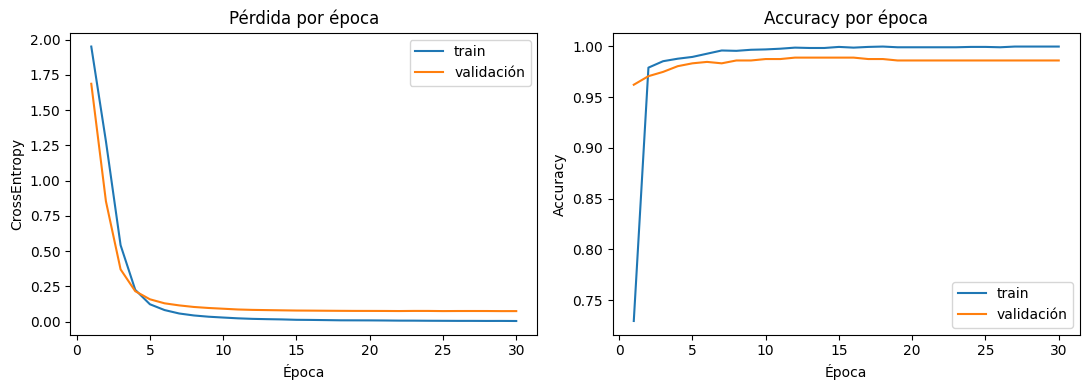

In [47]:
## 8. #curvas de pérdida y accuracy
epochs = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(epochs, history["train_loss"], label="train")
ax1.plot(epochs, history["val_loss"], label="validación")
ax1.set(title="Pérdida por época", xlabel="Época", ylabel="CrossEntropy")
ax1.legend()

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["val_acc"], label="validación")
ax2.set(title="Accuracy por época", xlabel="Época", ylabel="Accuracy")
ax2.legend()

fig.tight_layout()
fig.savefig("curves.png", dpi=150)
plt.show()

In [48]:
## 9. #evaluación final con el mejor modelo
model.load_state_dict(best_state)
val, y_true, y_pred = evaluate(model, val_loader, criterion, device)
print(f"Val loss {val['loss']:.4f} | Accuracy {val['accuracy']:.3f} | F1 macro {val['f1_macro']:.3f}\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

Val loss 0.0737 | Accuracy 0.986 | F1 macro 0.979

                         precision    recall  f1-score   support

     artefactos_cabello      0.992     1.000     0.996       129
       banos_sanitarios      1.000     1.000     1.000        91
           bazar_cocina      0.992     0.984     0.988       128
herramientas_electricas      1.000     0.903     0.949        31
            iluminacion      1.000     1.000     1.000       131
      jardin_aire_libre      0.952     0.952     0.952        62
                muebles      0.975     0.975     0.975        80
  peq_electrodomesticos      0.952     1.000     0.976        60

               accuracy                          0.986       712
              macro avg      0.983     0.977     0.979       712
           weighted avg      0.986     0.986     0.986       712



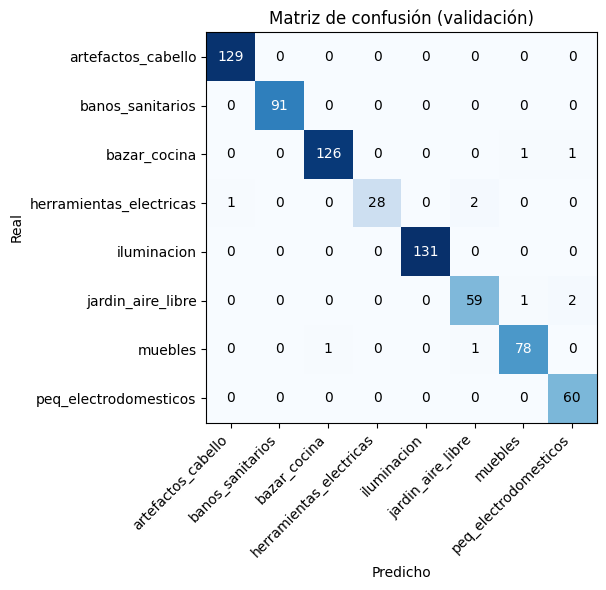

In [49]:
## 10. #matriz de confusión
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes)), classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set(title="Matriz de confusión (validación)", xlabel="Predicho", ylabel="Real")
fig.tight_layout()
plt.show()

In [50]:
## 11. #datos para el README
print("Versión de PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("learning_rate:", cfg.learning_rate)
print(f"Pérdida train: {history['train_loss'][0]:.4f} -> {history['train_loss'][-1]:.4f}")
print(f"Pérdida val:   {history['val_loss'][0]:.4f} -> {history['val_loss'][-1]:.4f}")
print("Mejor época (val loss):", int(np.argmin(history["val_loss"])) + 1)

Versión de PyTorch: 2.11.0+cpu
Dispositivo: cpu
learning_rate: 0.001
Pérdida train: 1.9519 -> 0.0036
Pérdida val:   1.6877 -> 0.0738
Mejor época (val loss): 29


## Resultados del experimento inicial

- **Versión de PyTorch**: 2.11.0+cpu
- **Dispositivo usado**: cpu
- **learning_rate**: 1e-3. Es el valor estándar de partida para Adam; con un MLP chico y batches de 64 permitió converger en pocas épocas sin oscilaciones.
- **Épocas**: 30 · **Batch size**: 64 · **Optimizador**: Adam
- **Pérdida de entrenamiento**: 1.9519 → 0.0036
- **Pérdida de validación**: 1.6877 → 0.0738
- **Mejor época (menor val loss)**: 29

**Métricas finales del mejor modelo (712 títulos de validación)**

| Métrica | Valor |
|---|---|
| Val loss | 0.0737 |
| Accuracy | 0.986 |
| F1 macro | 0.979 |


### Interpretación de la curva de pérdida
La pérdida bajó de forma sostenida tanto en entrenamiento (de 1.95 a 0.004) como en validación (de 1.69 a 0.074). La caída más fuerte ocurre en las primeras 10 épocas y después ambas curvas se aplanan. La pérdida de validación no aumentó en ningún momento, por lo que no se observa overfitting severo; sí hay una pequeña brecha entre train y validación (0.004 vs 0.074), esperable en un MLP con 5.000 features y ~2.800 ejemplos de entrenamiento. Al inicio la pérdida de validación es menor que la de train porque la de train se promedia durante la época, mientras el modelo todavía está aprendiendo y con Dropout activo.

La accuracy de validación superó 0.96 desde la primera época y se estabilizó en torno a 0.986. Los errores se concentran en las clases con menos datos: `herramientas_electricas` (recall 0.903, 31 ejemplos) y `jardin_aire_libre` (F1 0.952). El resultado es consistente con la sencillez de la tarea: una regresión logística sobre el mismo TF-IDF alcanza ≈0.985, lo que indica que el MLP aprende correctamente pero que el dataset es poco exigente.

In [38]:
pd.DataFrame(history).to_csv("history.csv", index_label="epoch")
from google.colab import files
files.download("curves.png")
files.download("history.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>